In [41]:
import os
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.preprocessing.image import load_img, img_to_array
import matplotlib.pyplot as plt

In [42]:
def load_data(data_dir, img_size=(128,128)):
    images =[]
    masks = []
    for img_file in os.listdir(data_dir):
        if '_mask' not in img_file:
            img_path = os.path.join(data_dir, img_file)
            mask_path = os.path.join(data_dir, img_file.replace('.jpg', '_mask.jpg'))
            img = load_img(img_path, target_size=img_size)
            mask = load_img(mask_path, target_size=img_size, color_mode='grayscale')

            img = img_to_array(img)/255.0
            mask = img_to_array(mask)/255.0

            images.append(img)
            masks.append(mask)
    return np.array(images), np.array(masks)

In [43]:
train_dir = '/kaggle/input/bp-dataset3/split_datasets/train'
val_dir = '/kaggle/input/bp-dataset3/split_datasets/val'
test_dir = '/kaggle/input/bp-dataset3/split_datasets/test'

X_train, y_train = load_data(train_dir)
X_val, y_val = load_data(val_dir)
X_test, y_test = load_data(test_dir)

In [44]:
def se_block(input_tensor, reduction=16):
    channel = input_tensor.shape[-1]  # 입력 텐서의 채널 수
    
    se = layers.GlobalAveragePooling2D()(input_tensor) # 채널별 평균값을 계산
    se = layers.Dense(channel // reduction, activation='relu')(se) # 채널 수를 감소시켜서 중요한 채널에 대한 정보를 압축
    se = layers.Dense(channel, activation='sigmoid')(se) # 다시 원래 채널 수로 확장하고, 시그모이드 함수를 통해 각 채널의 중요도를 얻음
    # 입력 텐서와 중요한 채널 정보(se)를 곱하여 채널 가중치를 조정
    return layers.multiply([input_tensor, se])

In [45]:
def build_unet(input_shape=(128,128,3),):
    inputs = layers.Input(input_shape)


    # encoder
    conv1 = layers.Conv2D(32,3, activation='relu', padding='same')(inputs)
    conv1 = layers.Conv2D(32,3, activation='relu', padding='same')(conv1)
    pool1 = layers.MaxPooling2D(pool_size=(2,2))(conv1)
    pool1 = layers.Dropout(0.4)(pool1)
    
    # dilated convolution
    conv2 = layers.Conv2D(64,3, activation='relu', padding='same', dilation_rate=(2,2))(pool1)
    conv2 = layers.Conv2D(64,3, activation='relu', padding='same', dilation_rate=(2,2))(conv2)
    pool2 = layers.MaxPooling2D(pool_size=(2,2))(conv2)
    pool2 = layers.Dropout(0.4)(pool2)

    conv3 = layers.Conv2D(128,3, activation='relu', padding='same')(pool2)
    conv3 = layers.Conv2D(128,3, activation='relu', padding='same')(conv3)
    pool3 = layers.MaxPooling2D(pool_size=(2,2))(conv3)
    pool3 = layers.Dropout(0.4)(pool3)

    # bridge
    conv4 = layers.Conv2D(256,3, activation='relu', padding='same', dilation_rate=(2,2))(pool3)
    conv4 = layers.Conv2D(256,3, activation='relu', padding='same', dilation_rate=(2,2))(conv4)
    
    # decoder
    up7 = layers.concatenate([layers.Conv2DTranspose(128, 2, strides=(2,2),padding='same')(conv4),conv3],axis=3)
    up7 = se_block(up7)
    conv7 = layers.Conv2D(128,3, activation='relu', padding='same')(up7)
    conv7 = layers.Conv2D(128,3, activation='relu', padding='same')(conv7)

    up8 = layers.concatenate([layers.Conv2DTranspose(64, 2, strides=(2,2),padding='same')(conv7),conv2],axis=3)
    up8 = se_block(up8)
    conv8 = layers.Conv2D(64,3, activation='relu', padding='same')(up8)
    conv8 = layers.Conv2D(64,3, activation='relu', padding='same')(conv8)

    up9 = layers.concatenate([layers.Conv2DTranspose(32, 2, strides=(2,2),padding='same')(conv8),conv1],axis=3)
    up9 = se_block(up9)
    conv9 = layers.Conv2D(32,3, activation='relu', padding='same')(up9)
    conv9 = layers.Conv2D(32,3, activation='relu', padding='same')(conv9)

    outputs = layers.Conv2D(1, 1, activation='sigmoid')(conv9)

    model = models.Model(inputs=inputs, outputs=outputs)
    
    return model

In [46]:
model = build_unet()
model.summary()

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)              ┃ Output Shape           ┃        Param # ┃ Connected to           ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer_4             │ (None, 128, 128, 3)    │              0 │ -                      │
│ (InputLayer)              │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2d_33 (Conv2D)        │ (None, 128, 128, 32)   │            896 │ input_layer_4[0][0]    │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2d_34 (Conv2D)        │ (None, 128, 128, 32)   │          9,248 │ conv2d_33[0][0]        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ max_pooling2d_7           │ (None, 64, 64, 32)     │              0 │ conv2d_34[0][0]        │
│ (MaxPooling2D)            │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ dropout_5 (Dropout)       │ (None, 64, 64, 32)     │              0 │ max_pooling2d_7[0][0]  │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2d_35 (Conv2D)        │ (None, 64, 64, 64)     │         18,496 │ dropout_5[0][0]        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2d_36 (Conv2D)        │ (None, 64, 64, 64)     │         36,928 │ conv2d_35[0][0]        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ max_pooling2d_8           │ (None, 32, 32, 64)     │              0 │ conv2d_36[0][0]        │
│ (MaxPooling2D)            │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ dropout_6 (Dropout)       │ (None, 32, 32, 64)     │              0 │ max_pooling2d_8[0][0]  │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2d_37 (Conv2D)        │ (None, 32, 32, 128)    │         73,856 │ dropout_6[0][0]        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2d_38 (Conv2D)        │ (None, 32, 32, 128)    │        147,584 │ conv2d_37[0][0]        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ max_pooling2d_9           │ (None, 16, 16, 128)    │              0 │ conv2d_38[0][0]        │
│ (MaxPooling2D)            │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ dropout_7 (Dropout)       │ (None, 16, 16, 128)    │              0 │ max_pooling2d_9[0][0]  │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2d_39 (Conv2D)        │ (None, 16, 16, 256)    │        295,168 │ dropout_7[0][0]        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2d_40 (Conv2D)        │ (None, 16, 16, 256)    │        590,080 │ conv2d_39[0][0]        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2d_transpose_6        │ (None, 32, 32, 128)    │        131,200 │ conv2d_40[0][0]        │
│ (Conv2DTranspose)         │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ concatenate_6             │ (None, 32, 32, 256)    │              0 │ conv2d_transpose_6[0]… │
│ (Concatenate)        

 Total params: 1,936,829 (7.39 MB)

 Trainable params: 1,936,829 (7.39 MB)

 Non-trainable params: 0 (0.00 B)

In [47]:
def dice_coef(y_true, y_pred, smooth=1e-6):
    y_pred = tf.cast(y_pred > 0.5, dtype=tf.int32)
    y_true = tf.cast(y_true, dtype=tf.float32)
    y_pred = tf.cast(y_pred, dtype=tf.float32)

    intersection = tf.reduce_sum(y_true * y_pred)
    intersection = tf.cast(intersection, dtype=tf.float32)
    
    y_true = tf.reduce_sum(y_true)
    y_pred = tf.reduce_sum(y_pred)

    result = (2.0 *(intersection) + smooth) / (y_true + y_pred + smooth)
    return result

def dice_loss(y_true, y_pred):
    return 1 - dice_coef(y_true, y_pred)
    
def combined_loss(y_true, y_pred, a=0.95):
    logit_loss_value = tf.keras.losses.binary_crossentropy(y_true, y_pred, from_logits=False)
    dice_loss_value = dice_loss(y_true, y_pred)
    return a * dice_loss_value + (1-a)*logit_loss_value

In [48]:
model.compile(optimizer = 'adam', loss=combined_loss,metrics=[dice_coef])

In [49]:
reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor='val_dice_coef',
    factor=0.9,
    patience=3,
    min_lr=1e-6,
    mode='max',
    verbose=1
)

model_checkpoint = tf.keras.callbacks.ModelCheckpoint(
    'best_unet_model.keras',
    monitor='val_dice_coef',
    save_best_only=True,
    mode='max',
    verbose=1
)

In [50]:
history = model.fit(X_train, y_train, batch_size=16, epochs=50, 
                    validation_data=(X_val, y_val),callbacks=[reduce_lr, model_checkpoint])

Epoch 1/50
37/38 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - dice_coef: 0.0148 - loss: 0.9596
Epoch 1: val_dice_coef improved from -inf to 0.00000, saving model to best_unet_model.keras
38/38 ━━━━━━━━━━━━━━━━━━━━ 14s 94ms/step - dice_coef: 0.0143 - loss: 0.9597 - val_dice_coef: 1.1786e-10 - val_loss: 0.9592 - learning_rate: 0.0010
Epoch 2/50
37/38 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - dice_coef: 1.2641e-10 - loss: 0.9582
Epoch 2: val_dice_coef did not improve from 0.00000
38/38 ━━━━━━━━━━━━━━━━━━━━ 1s 38ms/step - dice_coef: 1.2640e-10 - loss: 0.9581 - val_dice_coef: 1.1786e-10 - val_loss: 0.9563 - learning_rate: 0.0010
Epoch 3/50
37/38 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - dice_coef: 1.2697e-10 - loss: 0.9567
Epoch 3: val_dice_coef did not improve from 0.00000
38/38 ━━━━━━━━━━━━━━━━━━━━ 1s 38ms/step - dice_coef: 1.2695e-10 - loss: 0.9567 - val_dice_coef: 1.1786e-10 - val_loss: 0.9564 - learning_rate: 0.0010
Epoch 4/50
37/38 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - dice_coef: 0.0022 - loss: 0.9580
Epoch

In [51]:
best_model = tf.keras.models.load_model('best_unet_model.keras',
                                       custom_objects={'combined_loss':combined_loss, 'dice_coef' : dice_coef})

test_loss, test_dice = best_model.evaluate(X_test, y_test)

2/2 ━━━━━━━━━━━━━━━━━━━━ 2s 702ms/step - dice_coef: 0.6585 - loss: 0.3265


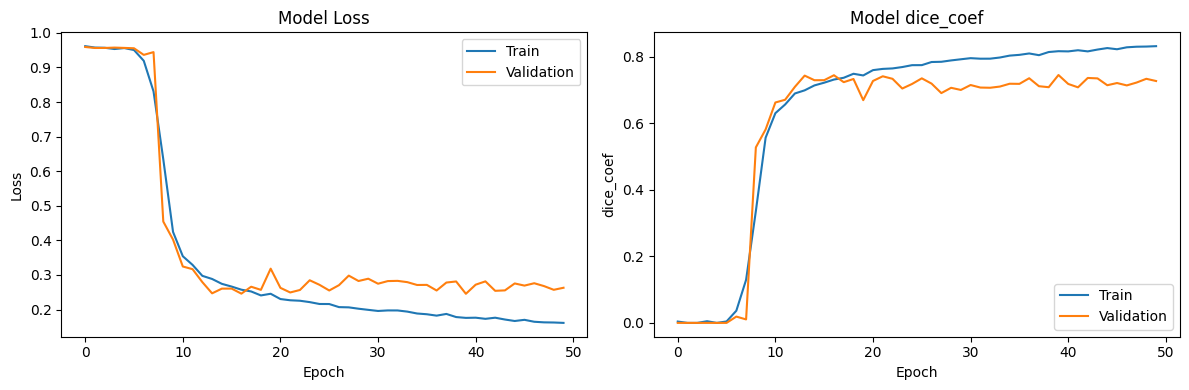

In [52]:
# ￿￿ ￿￿ ￿￿￿
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model Loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper right')
plt.subplot(1, 2, 2)
plt.plot(history.history['dice_coef'])
plt.plot(history.history['val_dice_coef'])

plt.title('Model dice_coef')
plt.ylabel('dice_coef')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='lower right')
plt.tight_layout()

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 777ms/step


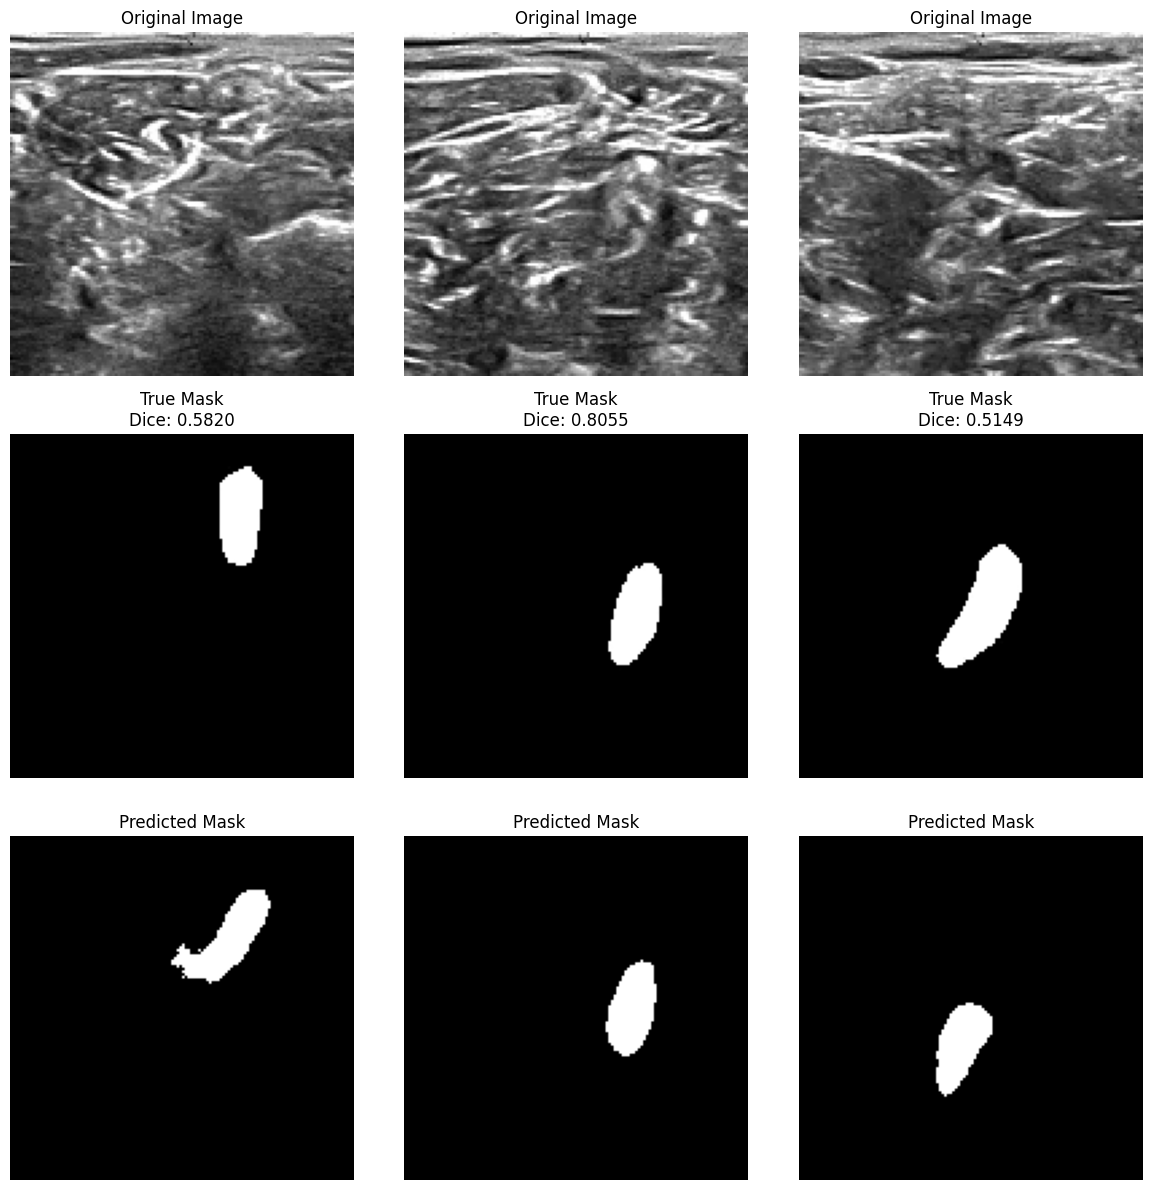

In [54]:
def visualize_results(model, X, y, num_samples=3):
    predictions = model.predict(X[:num_samples])
    predictions = (predictions > 0.5).astype(np.float32)

    plt.figure(figsize=(4*num_samples, 12))
    for i in range(num_samples):
        plt.subplot(3, num_samples, i+1)
        plt.imshow(X[i])
        plt.title('Original Image')
        plt.axis('off')
        
        plt.subplot(3, num_samples, i+1+num_samples)
        plt.imshow(y[i, :, :, 0], cmap='gray')
        plt.title(f'True Mask\nDice: {dice_coef(y[i:i+1], predictions[i:i+1]).numpy():.4f}')
        plt.axis('off')
        
        plt.subplot(3, num_samples, i+1+2*num_samples)
        plt.imshow(predictions[i, :, :, 0], cmap='gray')
        plt.title('Predicted Mask')
        plt.axis('off')

    plt.tight_layout()
    plt.show()

visualize_results(best_model, X_test, y_test)

In [56]:
best_model.save('dropout.h5')